# Deep Learning — Classification Multi-Classes QWS (Bronze / Silver / Gold)

**Objectif** : Entraîner un réseau de neurones MLP (Multi-Layer Perceptron) avec **PyTorch** pour classifier les services web en 3 classes de qualité QoS : **Bronze**, **Silver**, **Gold**.

**Dataset d'entrée** : `qws2_avec_class.csv` généré par le notebook de clustering.

| Étape | Description |
|---|---|
| Input | 9 attributs QoS (ResponseTime, Availability, …) |
| Output | 3 classes : Bronze (0) / Silver (1) / Gold (2) |
| Architecture | MLP : 9 → 128 → 64 → 32 → 3 |
| Loss | CrossEntropyLoss |
| Optimizer | Adam |

## 1. Import des bibliothèques

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, ConfusionMatrixDisplay)
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import warnings
warnings.filterwarnings('ignore')

# Reproductibilité
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device utilisé : {device}")
print(f"PyTorch version : {torch.__version__}")
print("Bibliothèques importées ✔")

Device utilisé : cuda
PyTorch version : 2.4.1+cu124
Bibliothèques importées ✔


## 2. Chargement et exploration du dataset labelisé

In [2]:
df = pd.read_csv('qws2_avec_class.csv')

print(f"Shape : {df.shape}")
print(f"\nColonnes : {list(df.columns)}")
print(f"\nDistribution des classes :")
print(df['class'].value_counts())
print(f"\nValeurs manquantes :\n{df.isnull().sum()[df.isnull().sum() > 0]}")

df.head()

Shape : (2507, 12)

Colonnes : ['ResponseTime', 'Availability', 'Throughput', 'Successability', 'Reliability', 'Compliance', 'BestPractices', 'Latency', 'Documentation', 'ServiceName', 'WSDLAddress', 'class']

Distribution des classes :
class
Gold      1413
Silver     593
Bronze     501
Name: count, dtype: int64

Valeurs manquantes :
Series([], dtype: int64)


,ResponseTime,Availability,Throughput,Successability,Reliability,Compliance,BestPractices,Latency,Documentation,ServiceName,WSDLAddress,class
0,302.75,89,7.1,90,73,78,80,187.75,32,MAPPMatching,http://xml.assessment.com/service/MAPPMatching...,Gold
1,482.00,85,16.0,95,73,100,84,1.00,2,Compound2,http://www.mssoapinterop.org/asmx/WSDL/compoun...,Gold
2,3321.40,89,1.4,96,73,78,80,2.60,96,USDAData,http://www.strikeiron.com/webservices/usdadata...,Gold
3,126.17,98,12.0,100,67,78,82,22.77,89,GBNIRHolidayDates,http://www.holidaywebservice.com/Holidays/GBNI...,Gold
4,107.00,87,1.9,95,73,89,62,58.33,93,CasUsers,http://galex.stsci.edu/casjobs/CasUsers.asmx?WSDL,Silver


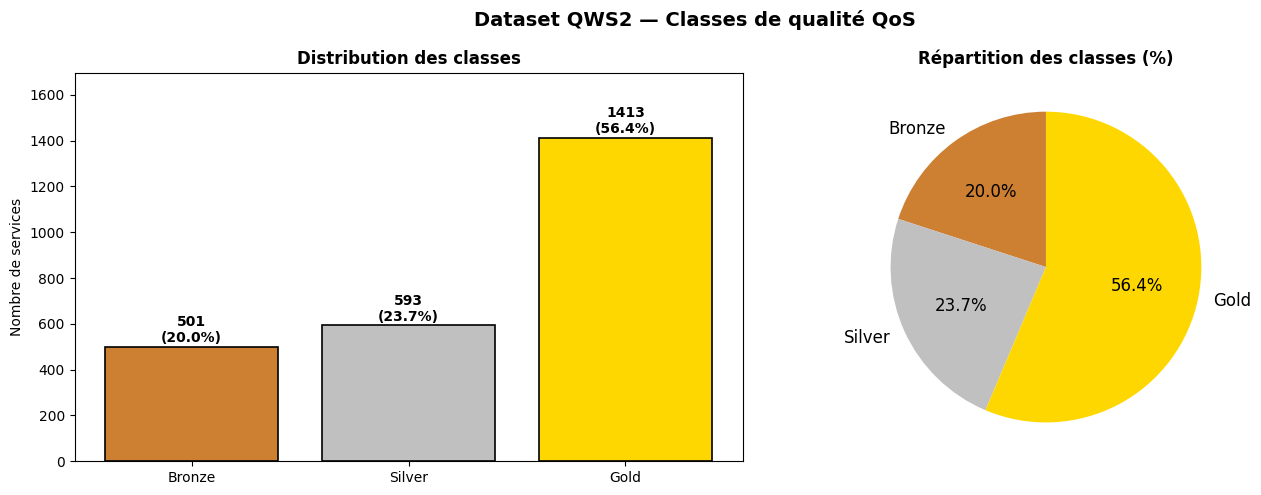

In [3]:
# Visualisation de la distribution des classes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

color_map = {'Bronze': '#CD7F32', 'Silver': '#C0C0C0', 'Gold': '#FFD700'}
classes_order = ['Bronze', 'Silver', 'Gold']
counts = [df[df['class'] == c].shape[0] for c in classes_order]

# Bar chart
bars = axes[0].bar(classes_order, counts,
                   color=[color_map[c] for c in classes_order],
                   edgecolor='black', linewidth=1.2)
axes[0].set_title('Distribution des classes', fontweight='bold')
axes[0].set_ylabel('Nombre de services')
for bar, cnt in zip(bars, counts):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 f'{cnt}\n({cnt/sum(counts)*100:.1f}%)',
                 ha='center', va='bottom', fontweight='bold', fontsize=10)
axes[0].set_ylim(0, max(counts) * 1.2)

# Pie chart
axes[1].pie(counts, labels=classes_order, autopct='%1.1f%%',
            colors=[color_map[c] for c in classes_order],
            startangle=90, textprops={'fontsize': 12})
axes[1].set_title('Répartition des classes (%)', fontweight='bold')

plt.suptitle('Dataset QWS2 — Classes de qualité QoS', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Prétraitement — Encodage & Normalisation & Split

In [4]:
qos_cols = ['ResponseTime', 'Availability', 'Throughput', 'Successability',
            'Reliability', 'Compliance', 'BestPractices', 'Latency', 'Documentation']

# --- Features et labels ---
X = df[qos_cols].values.astype(np.float32)

# Encodage des labels : Bronze=0, Silver=1, Gold=2
le = LabelEncoder()
le.fit(['Bronze', 'Silver', 'Gold'])          # ordre fixé
y = le.transform(df['class'].values)
print(f"Classes encodées : {dict(zip(le.classes_, le.transform(le.classes_)))}")

# --- Normalisation (StandardScaler) ---
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X).astype(np.float32)

# --- Split : 70% train | 15% val | 15% test ---
X_train, X_temp, y_train, y_temp = train_test_split(
    X_scaled, y, test_size=0.30, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

print(f"\nSplit du dataset :")
print(f"  Train : {X_train.shape[0]} exemples ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"  Val   : {X_val.shape[0]} exemples   ({X_val.shape[0]/len(X)*100:.1f}%)")
print(f"  Test  : {X_test.shape[0]} exemples  ({X_test.shape[0]/len(X)*100:.1f}%)")
print(f"\nDimension input  : {X_train.shape[1]} features")
print(f"Nombre de classes : {len(le.classes_)}")

Classes encodées : {'Bronze': 0, 'Gold': 1, 'Silver': 2}

Split du dataset :
  Train : 1754 exemples (70.0%)
  Val   : 376 exemples   (15.0%)
  Test  : 377 exemples  (15.0%)

Dimension input  : 9 features
Nombre de classes : 3


## 4. Dataset PyTorch & DataLoaders

In [5]:
class QWSDataset(Dataset):
    """Dataset PyTorch pour les services web QWS."""
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


BATCH_SIZE = 64

train_ds  = QWSDataset(X_train, y_train)
val_ds    = QWSDataset(X_val,   y_val)
test_ds   = QWSDataset(X_test,  y_test)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False)

print(f"Batch size     : {BATCH_SIZE}")
print(f"Train batches  : {len(train_loader)}")
print(f"Val   batches  : {len(val_loader)}")
print(f"Test  batches  : {len(test_loader)}")
print("DataLoaders prêts ✔")

Batch size     : 64
Train batches  : 28
Val   batches  : 6
Test  batches  : 6
DataLoaders prêts ✔


## 5. Architecture du modèle MLP

```
Input (9)  →  Dense(128, ReLU, BN, Dropout 0.3)
           →  Dense(64,  ReLU, BN, Dropout 0.2)
           →  Dense(32,  ReLU, BN)
           →  Output(3, Softmax via CrossEntropyLoss)
```

In [6]:
class QoSClassifier(nn.Module):
    """MLP pour la classification multi-classes QoS."""

    def __init__(self, input_dim=9, num_classes=3):
        super(QoSClassifier, self).__init__()

        self.network = nn.Sequential(
            # Couche 1 : 9 → 128
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            # Couche 2 : 128 → 64
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            # Couche 3 : 64 → 32
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),

            # Couche sortie : 32 → 3
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        return self.network(x)


# Instanciation du modèle
INPUT_DIM   = X_train.shape[1]   # 9
NUM_CLASSES = len(le.classes_)   # 3

model = QoSClassifier(input_dim=INPUT_DIM, num_classes=NUM_CLASSES).to(device)

# Résumé du modèle
print(model)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nNombre total de paramètres : {total_params:,}")

QoSClassifier(
  (network): Sequential(
    (0): Linear(in_features=9, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Linear(in_features=32, out_features=3, bias=True)
  )
)

Nombre total de paramètres : 12,163


## 6. Configuration de l'entraînement

In [7]:
# Hyperparamètres
EPOCHS    = 150
LR        = 1e-3
PATIENCE  = 20   # Early stopping

# Poids de classes pour équilibrer (utile si déséquilibre)
class_counts = np.bincount(y_train)
class_weights = torch.tensor(1.0 / class_counts, dtype=torch.float32).to(device)
class_weights = class_weights / class_weights.sum() * NUM_CLASSES

# Loss, Optimizer, Scheduler
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=10, verbose=True)

print(f"Epochs      : {EPOCHS}")
print(f"Learning rate : {LR}")
print(f"Early stopping patience : {PATIENCE}")
print(f"Poids des classes : {class_weights.cpu().numpy().round(4)}")
print("Configuration prête ✔")

Epochs      : 150
Learning rate : 0.001
Early stopping patience : 20
Poids des classes : [1.3653 0.4832 1.1515]
Configuration prête ✔


## 7. Boucle d'entraînement

In [8]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y_batch)
        preds = logits.argmax(dim=1)
        correct += (preds == y_batch).sum().item()
        total   += len(y_batch)
    return total_loss / total, correct / total


def eval_epoch(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            total_loss += loss.item() * len(y_batch)
            preds = logits.argmax(dim=1)
            correct += (preds == y_batch).sum().item()
            total   += len(y_batch)
    return total_loss / total, correct / total


# ─── Entraînement ─────────────────────────────────────────────────────────────
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_loss = float('inf')
patience_counter = 0

print(f"{'Epoch':>6} | {'Train Loss':>10} | {'Train Acc':>9} | {'Val Loss':>8} | {'Val Acc':>7}")
print("-" * 56)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    vl_loss, vl_acc = eval_epoch(model, val_loader, criterion, device)
    scheduler.step(vl_loss)

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(vl_acc)

    if epoch % 10 == 0 or epoch == 1:
        print(f"{epoch:>6} | {tr_loss:>10.4f} | {tr_acc*100:>8.2f}% | {vl_loss:>8.4f} | {vl_acc*100:>6.2f}%")

    # Early stopping
    if vl_loss < best_val_loss:
        best_val_loss = vl_loss
        patience_counter = 0
        torch.save(model.state_dict(), 'mlp_qws_best.pth')
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\n⏹ Early stopping à l'epoch {epoch} (patience={PATIENCE})")
            break

print(f"\n✅ Entraînement terminé — Meilleur val_loss : {best_val_loss:.4f}")

 Epoch | Train Loss | Train Acc | Val Loss | Val Acc
--------------------------------------------------------
     1 |     0.7754 |    73.15% |   0.5426 |  93.62%
    10 |     0.1302 |    94.81% |   0.0917 |  96.54%
    20 |     0.1212 |    95.44% |   0.0762 |  97.07%
    30 |     0.1036 |    95.95% |   0.0745 |  96.54%
    40 |     0.1012 |    95.32% |   0.0666 |  97.61%
    50 |     0.0697 |    96.81% |   0.0668 |  97.61%
    60 |     0.0725 |    97.26% |   0.0542 |  98.14%

⏹ Early stopping à l'epoch 68 (patience=20)

✅ Entraînement terminé — Meilleur val_loss : 0.0534


## 8. Courbes d'apprentissage

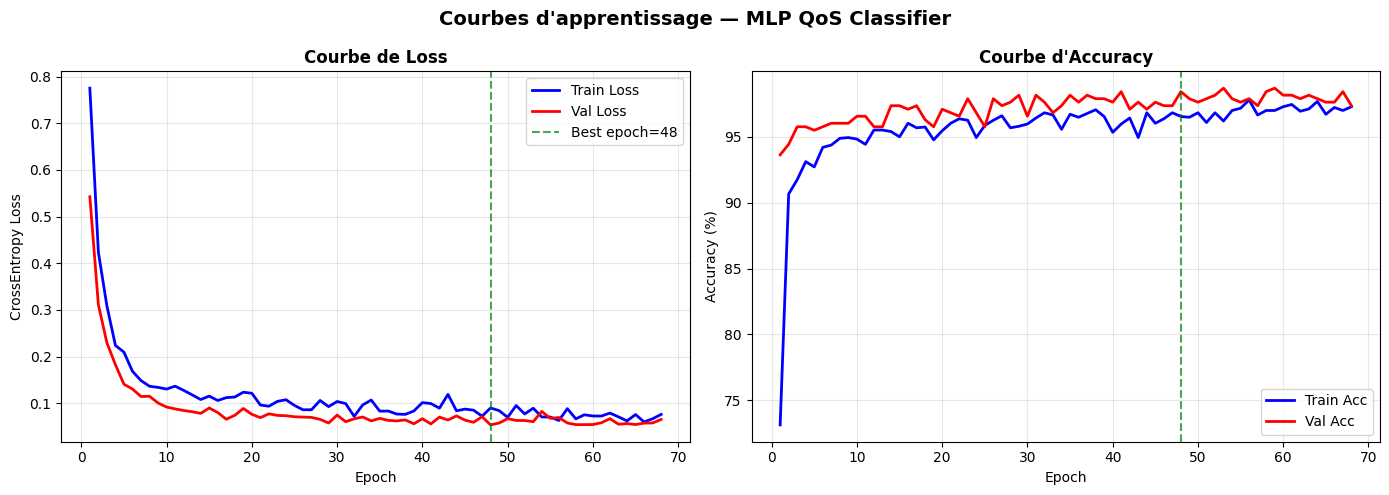

Meilleur epoch    : 48
Meilleur val_loss : 0.0534
Meilleur val_acc  : 98.67%


In [9]:
epochs_ran = range(1, len(history['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Loss ---
ax1.plot(epochs_ran, history['train_loss'], 'b-', label='Train Loss', linewidth=2)
ax1.plot(epochs_ran, history['val_loss'],   'r-', label='Val Loss',   linewidth=2)
best_ep = np.argmin(history['val_loss']) + 1
ax1.axvline(x=best_ep, color='green', linestyle='--', alpha=0.7,
            label=f'Best epoch={best_ep}')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('CrossEntropy Loss')
ax1.set_title('Courbe de Loss', fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

# --- Accuracy ---
ax2.plot(epochs_ran, [a*100 for a in history['train_acc']], 'b-', label='Train Acc', linewidth=2)
ax2.plot(epochs_ran, [a*100 for a in history['val_acc']],   'r-', label='Val Acc',   linewidth=2)
ax2.axvline(x=best_ep, color='green', linestyle='--', alpha=0.7)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_title("Courbe d'Accuracy", fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.suptitle('Courbes d\'apprentissage — MLP QoS Classifier',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('qws_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Meilleur epoch    : {best_ep}")
print(f"Meilleur val_loss : {min(history['val_loss']):.4f}")
print(f"Meilleur val_acc  : {max(history['val_acc'])*100:.2f}%")

## 9. Évaluation sur le jeu de test

In [10]:
# Charger le meilleur modèle sauvegardé
model.load_state_dict(torch.load('mlp_qws_best.pth', map_location=device))
model.eval()

# Prédictions sur le test set
all_preds, all_labels = [], []
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        logits = model(X_batch)
        preds  = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(y_batch.numpy())

y_pred = np.array(all_preds)
y_true = np.array(all_labels)
class_names = le.classes_   # ['Bronze', 'Gold', 'Silver'] selon LabelEncoder

# ─── Métriques ────────────────────────────────────────────────────────────────
test_acc = accuracy_score(y_true, y_pred)
print(f"{'='*55}")
print(f"  ACCURACY SUR LE TEST SET : {test_acc*100:.2f}%")
print(f"{'='*55}")
print()
print("=== Rapport de classification ===")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

  ACCURACY SUR LE TEST SET : 97.88%

=== Rapport de classification ===
              precision    recall  f1-score   support

      Bronze     0.9605    0.9605    0.9605        76
        Gold     0.9952    0.9811    0.9881       212
      Silver     0.9565    0.9888    0.9724        89

    accuracy                         0.9788       377
   macro avg     0.9708    0.9768    0.9737       377
weighted avg     0.9791    0.9788    0.9788       377



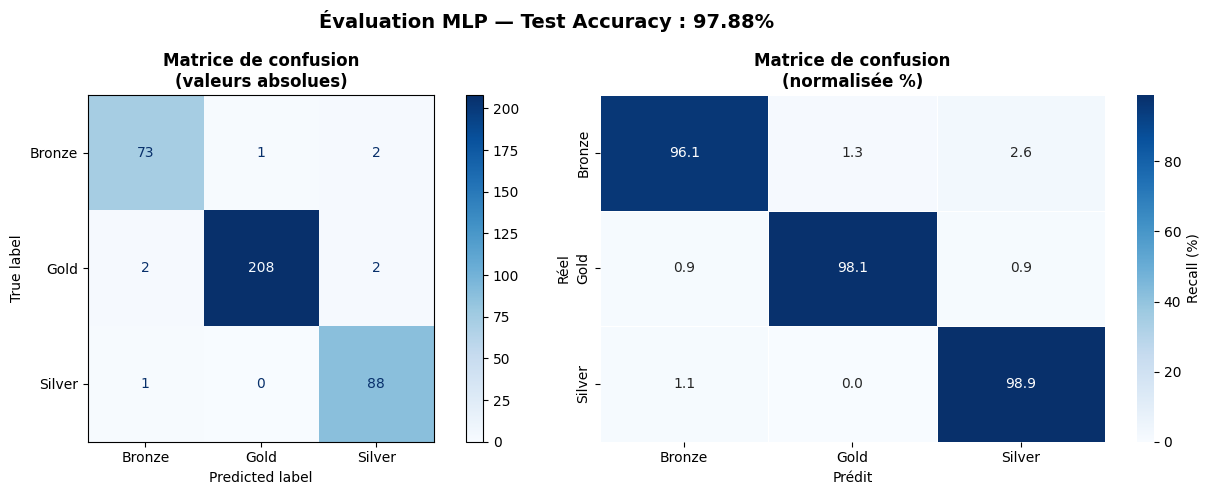

In [11]:
# ─── Matrice de confusion ─────────────────────────────────────────────────────
cm = confusion_matrix(y_true, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matrice de confusion absolue
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=axes[0], colorbar=True, cmap='Blues')
axes[0].set_title('Matrice de confusion\n(valeurs absolues)', fontweight='bold')

# Matrice de confusion normalisée (%)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
sns.heatmap(cm_norm, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            ax=axes[1], linewidths=0.5,
            cbar_kws={'label': 'Recall (%)'})
axes[1].set_xlabel('Prédit')
axes[1].set_ylabel('Réel')
axes[1].set_title('Matrice de confusion\n(normalisée %)', fontweight='bold')

plt.suptitle(f'Évaluation MLP — Test Accuracy : {test_acc*100:.2f}%',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('qws_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Importance des features (Permutation Importance)

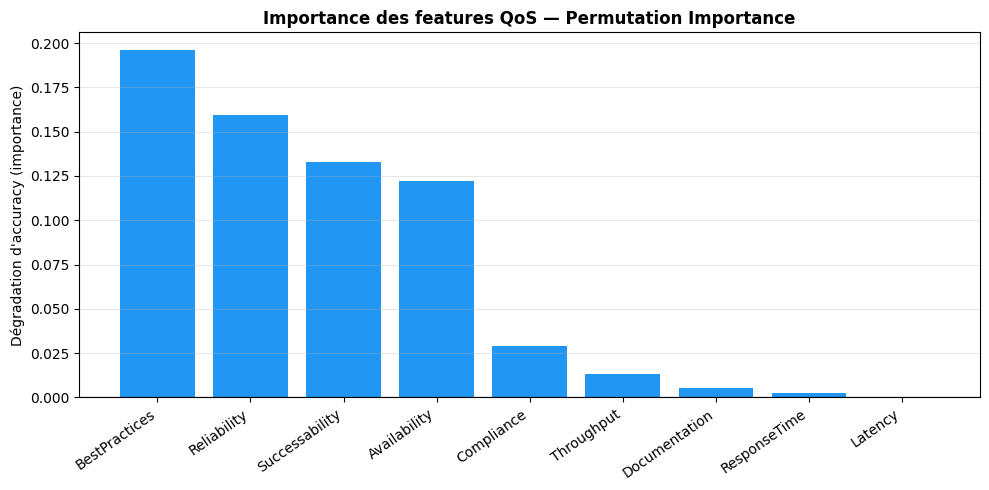


Base accuracy  : 97.88%

Ranking des features par importance :
   1. BestPractices        : +0.1963
   2. Reliability          : +0.1592
   3. Successability       : +0.1326
   4. Availability         : +0.1220
   5. Compliance           : +0.0292
   6. Throughput           : +0.0133
   7. Documentation        : +0.0053
   8. ResponseTime         : +0.0027
   9. Latency              : +0.0000


In [12]:
"""
Permutation Importance : on mélange chaque feature une par une et on mesure
la dégradation d'accuracy → plus la dégradation est grande, plus la feature est importante.
"""
model.eval()
X_test_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)
y_test_tensor = torch.tensor(y_test, dtype=torch.long).to(device)

# Accuracy de base
with torch.no_grad():
    base_preds = model(X_test_tensor).argmax(dim=1)
base_acc = (base_preds == y_test_tensor).float().mean().item()

importances = []
for i in range(X_test.shape[1]):
    X_permuted = X_test_tensor.clone()
    # Permutation aléatoire de la feature i
    perm_idx = torch.randperm(X_permuted.shape[0])
    X_permuted[:, i] = X_permuted[perm_idx, i]
    with torch.no_grad():
        perm_preds = model(X_permuted).argmax(dim=1)
    perm_acc = (perm_preds == y_test_tensor).float().mean().item()
    importances.append(base_acc - perm_acc)

# Visualisation
feat_names = ['ResponseTime', 'Availability', 'Throughput', 'Successability',
              'Reliability', 'Compliance', 'BestPractices', 'Latency', 'Documentation']
sorted_idx = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 5))
colors = ['#2196F3' if imp >= 0 else '#F44336' for imp in np.array(importances)[sorted_idx]]
plt.bar(range(len(feat_names)), np.array(importances)[sorted_idx], color=colors)
plt.xticks(range(len(feat_names)), [feat_names[i] for i in sorted_idx], rotation=35, ha='right')
plt.ylabel('Dégradation d\'accuracy (importance)')
plt.title('Importance des features QoS — Permutation Importance', fontweight='bold')
plt.axhline(y=0, color='black', linewidth=0.8)
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('qws_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nBase accuracy  : {base_acc*100:.2f}%")
print("\nRanking des features par importance :")
for rank_i, idx in enumerate(sorted_idx):
    print(f"  {rank_i+1:2}. {feat_names[idx]:<20} : {importances[idx]:+.4f}")

## 11. Sauvegarde du modèle & inférence sur un nouveau service

In [13]:
import pickle

# ─── Sauvegarde ───────────────────────────────────────────────────────────────
torch.save(model.state_dict(), 'mlp_qws_classifier.pth')

# Sauvegarder aussi le scaler et le label encoder (nécessaires en production)
with open('qws_scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
with open('qws_label_encoder.pkl', 'wb') as f:
    pickle.dump(le, f)

print("Modèle sauvegardé         : mlp_qws_classifier.pth")
print("Scaler sauvegardé         : qws_scaler.pkl")
print("LabelEncoder sauvegardé   : qws_label_encoder.pkl")

# ─── Exemple d'inférence sur un nouveau service ───────────────────────────────
print("\n" + "="*55)
print("  EXEMPLE D'INFÉRENCE SUR UN NOUVEAU SERVICE WEB")
print("="*55)

# Exemple : service avec bonnes performances (proche Gold)
nouveau_service = {
    'ResponseTime': 80,       # rapide (bas = bien)
    'Availability': 99,       # très disponible
    'Throughput': 20,         # bon débit
    'Successability': 99,     # très fiable
    'Reliability': 83,        # fiable
    'Compliance': 100,        # conforme
    'BestPractices': 91,      # bonnes pratiques
    'Latency': 2,             # faible latence (bas = bien)
    'Documentation': 90       # bien documenté
}

x_new = np.array(list(nouveau_service.values())).reshape(1, -1).astype(np.float32)
x_new_scaled = scaler.transform(x_new)
x_tensor = torch.tensor(x_new_scaled, dtype=torch.float32).to(device)

model.eval()
with torch.no_grad():
    logits     = model(x_tensor)
    probs      = torch.softmax(logits, dim=1).cpu().numpy()[0]
    pred_class = le.inverse_transform([logits.argmax(dim=1).item()])[0]

print(f"\nService : {nouveau_service}")
print(f"\nProbabilités par classe :")
for cls, prob in zip(le.classes_, probs):
    bar = '█' * int(prob * 30)
    print(f"  {cls:<8} : {prob*100:6.2f}%  {bar}")
print(f"\n→ Classe prédite : ⭐ {pred_class} ⭐")

Modèle sauvegardé         : mlp_qws_classifier.pth
Scaler sauvegardé         : qws_scaler.pkl
LabelEncoder sauvegardé   : qws_label_encoder.pkl

  EXEMPLE D'INFÉRENCE SUR UN NOUVEAU SERVICE WEB

Service : {'ResponseTime': 80, 'Availability': 99, 'Throughput': 20, 'Successability': 99, 'Reliability': 83, 'Compliance': 100, 'BestPractices': 91, 'Latency': 2, 'Documentation': 90}

Probabilités par classe :
  Bronze   :   0.01%  
  Gold     :  99.98%  █████████████████████████████
  Silver   :   0.01%  

→ Classe prédite : ⭐ Gold ⭐
